<a href="https://colab.research.google.com/github/U-mar-404/PE-LLM-Lab05-rnn/blob/main/Prompt_Eng_Lab_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 231243
#Muhammad Umar

# Task 1

Libraries



In [8]:
import re
import numpy as np
import tensorflow as tf

Download dataset

In [9]:
!wget -q http://www.manythings.org/anki/fra-eng.zip
!unzip -o -q fra-eng.zip

Load and clean data

In [10]:
def clean(text):
    text = text.lower()
    text = re.sub(r"[^\w\s]", "", text)
    return text.strip()

pairs = []
with open("fra.txt", encoding="utf-8") as f:
    for line in f.readlines()[:10000]:
        eng, fra = line.split("\t")[:2]
        eng, fra = clean(eng), clean(fra)
        if 3 <= len(eng.split()) <= 6 and 3 <= len(fra.split()) <= 6:
            pairs.append((eng, "<start> " + fra + " <end>"))

eng_texts, fra_texts = zip(*pairs)
print(len(pairs))
print(pairs[:3])

4499
[('be a man', '<start> sois un homme <end>'), ('be a man', '<start> soyez un homme <end>'), ('can i go', '<start> je peux y aller <end>')]


Tokenizers, vocabularies, padding

In [11]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

eng_tok = Tokenizer(filters="")
eng_tok.fit_on_texts(eng_texts)
fra_tok = Tokenizer(filters="")
fra_tok.fit_on_texts(fra_texts)

eng_vocab = len(eng_tok.word_index) + 1
fra_vocab = len(fra_tok.word_index) + 1

enc_in = pad_sequences(eng_tok.texts_to_sequences(eng_texts), padding="post")
fra_seq = fra_tok.texts_to_sequences(fra_texts)
dec_in = pad_sequences([s[:-1] for s in fra_seq], padding="post")
dec_out = pad_sequences([s[1:] for s in fra_seq], padding="post")

print(eng_vocab, fra_vocab, enc_in.shape, dec_in.shape)

1257 2378 (4499, 4) (4499, 7)


Build the encoder-decoder model

In [12]:
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dense
from tensorflow.keras.models import Model

def build_model(units, emb):
    enc_inp = Input(shape=(enc_in.shape[1],))
    x = Embedding(eng_vocab, emb, mask_zero=True)(enc_inp)
    _, state = SimpleRNN(units, return_state=True)(x)

    dec_inp = Input(shape=(dec_in.shape[1],))
    y = Embedding(fra_vocab, emb, mask_zero=True)(dec_inp)
    y = SimpleRNN(units, return_sequences=True)(y, initial_state=state)
    out = Dense(fra_vocab, activation="softmax")(y)

    model = Model([enc_inp, dec_inp], out)
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model = build_model(128, 64)
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_5       │ (None, 7)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_4         │ (None, 4, 64)     │     80,448 │ input_layer_4[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_4         │ (None, 4)         │          0 │ input_layer_4[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_5         │ (None, 7, 64)     │    152,192 │ input_layer_5[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_4        │ [(None, 128),     │     24,704 │ embedding_4[0][0… │
│ (SimpleRNN)         │ (None, 128)]      │            │ not_equal_4[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_5        │ (None, 7, 128)    │     24,704 │ embedding_5[0][0… │
│ (SimpleRNN)         │                   │            │ simple_rnn_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 7, 2378)   │    306,762 │ simple_rnn_5[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 588,810 (2.25 MB)

 Trainable params: 588,810 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

Train

In [13]:
history = model.fit([enc_in, dec_in], dec_out, batch_size=64, epochs=20, validation_split=0.1)

Epoch 1/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.2536 - loss: 5.7072 - val_accuracy: 0.2129 - val_loss: 5.1065
Epoch 2/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2927 - loss: 4.4810 - val_accuracy: 0.2431 - val_loss: 4.8547
Epoch 3/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3101 - loss: 4.2245 - val_accuracy: 0.2625 - val_loss: 4.6615
Epoch 4/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3515 - loss: 3.9544 - val_accuracy: 0.3822 - val_loss: 4.4393
Epoch 5/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3784 - loss: 3.7170 - val_accuracy: 0.3940 - val_loss: 4.3086
Epoch 6/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3938 - loss: 3.5135 - val_accuracy: 0.4021 - val_loss: 4.1740
Epoch 7/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4101 - loss: 3.3370 - val_accuracy: 0.4016 - val_loss: 4.1072
Epoch 8/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4274 - loss: 3.1674 - val_accuracy: 0.4149 - val_loss

Inference loop and 10 translations

In [14]:
def translate(sentence):
    seq = pad_sequences(eng_tok.texts_to_sequences([clean(sentence)]), maxlen=enc_in.shape[1], padding="post")
    dec = np.zeros((1, dec_in.shape[1]))
    dec[0, 0] = fra_tok.word_index["<start>"]
    words = []
    for i in range(dec.shape[1]):
        pred = model.predict([seq, dec], verbose=0)[0, i].argmax()
        word = fra_tok.index_word.get(pred, "")
        if word == "<end>" or word == "":
            break
        words.append(word)
        if i + 1 < dec.shape[1]:
            dec[0, i + 1] = pred
    return " ".join(words)

step = len(eng_texts) // 10
for s in eng_texts[::step][:10]:
    print(s, "->", translate(s))

be a man -> fais un boulot
did tom eat -> tom estil ici
is it yours -> estce de lamour
go to school -> va à vous
ill grab it -> je le tuerai
tom is a man -> tom est malade
dont push it -> ne le fais pas
i know myself -> je me suis senti mal
ive got eyes -> je lai vu
take only one -> prendsen seulement une


Experiments (hidden units and embedding dimension)

In [15]:
for units in [64, 128, 256]:
    m = build_model(units, 64)
    h = m.fit([enc_in, dec_in], dec_out, batch_size=64, epochs=10, validation_split=0.1, verbose=0)
    print("units", units, "val_acc", round(h.history["val_accuracy"][-1], 4))

for emb in [32, 64, 128]:
    m = build_model(128, emb)
    h = m.fit([enc_in, dec_in], dec_out, batch_size=64, epochs=10, validation_split=0.1, verbose=0)
    print("embedding", emb, "val_acc", round(h.history["val_accuracy"][-1], 4))

units 64 val_acc 0.3969
units 128 val_acc 0.4201
units 256 val_acc 0.4489
embedding 32 val_acc 0.4054
embedding 64 val_acc 0.4186
embedding 128 val_acc 0.429


Short (≤4 words) vs longer (≥6 words) sentences

In [16]:
lens = np.array([len(s.split()) for s in eng_texts])
short = lens <= 4
long = lens >= 6

print("short:", model.evaluate([enc_in[short], dec_in[short]], dec_out[short], verbose=0))
print("long:", model.evaluate([enc_in[long], dec_in[long]], dec_out[long], verbose=0))

short: [1.885068655014038, 0.610200047492981]
long: []


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


# Task 2

Libraries

In [17]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

Load and clean data

In [19]:
df = pd.read_csv("https://huggingface.co/datasets/osanseviero/twitter-airline-sentiment/resolve/main/Tweets.csv")[["text", "airline_sentiment"]]

def clean(text):
    text = text.lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"[^a-z\s]", "", text)
    return text.strip()

df["text"] = df["text"].apply(clean)
names = ["negative", "neutral", "positive"]
df["label"] = df["airline_sentiment"].map({n: i for i, n in enumerate(names)})
print(df["label"].value_counts())

label
0    9178
1    3099
2    2363
Name: count, dtype: int64


Train / validation / test split

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(df["text"], df["label"], test_size=0.3, stratify=df["label"], random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
print(len(X_train), len(X_val), len(X_test))

10248 2196 2196


Tokenizer, integer encoding, padding

In [21]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

tok = Tokenizer(num_words=10000, oov_token="<oov>")
tok.fit_on_texts(X_train)

def encode(texts, max_len):
    return pad_sequences(tok.texts_to_sequences(texts), maxlen=max_len, padding="pre")

Model builder

In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dropout, Dense
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

def build_model(max_len, units=32, dropout=0.5):
    model = Sequential([
        Input(shape=(max_len,)),
        Embedding(10000, 32, embeddings_regularizer=l2(1e-4)),
        SimpleRNN(units, dropout=0.3, recurrent_dropout=0.3, kernel_regularizer=l2(5e-3)),
        Dropout(dropout),
        Dense(3, activation="softmax", kernel_regularizer=l2(1e-3))
    ])
    model.compile(optimizer=Adam(5e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

Train

In [32]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

max_len = 40
Xtr, Xv, Xte = encode(X_train, max_len), encode(X_val, max_len), encode(X_test, max_len)

model = build_model(max_len)
model.summary()
callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1)
]
history = model.fit(Xtr, y_train, validation_data=(Xv, y_val), epochs=30, batch_size=64, callbacks=callbacks)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_20 (Embedding)        │ (None, 40, 32)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_20 (SimpleRNN)       │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 322,179 (1.23 MB)

 Trainable params: 322,179 (1.23 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 14s 55ms/step - accuracy: 0.3675 - loss: 1.3669 - val_accuracy: 0.6047 - val_loss: 1.1686 - learning_rate: 5.0000e-04
Epoch 2/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.4582 - loss: 1.2266 - val_accuracy: 0.6266 - val_loss: 1.0675 - learning_rate: 5.0000e-04
Epoch 3/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.5457 - loss: 1.1435 - val_accuracy: 0.6266 - val_loss: 1.0427 - learning_rate: 5.0000e-04
Epoch 4/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.5824 - loss: 1.1014 - val_accuracy: 0.6266 - val_loss: 1.0253 - learning_rate: 5.0000e-04
Epoch 5/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6050 - loss: 1.0673 - val_accuracy: 0.6266 - val_loss: 1.0126 - learning_rate: 5.0000e-04
Epoch 6/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.6153 - loss: 1.0465 - val_accuracy: 0.6266 - val_loss: 0.9996 - learning_rate: 5.0000e-04
Epoch 7/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accur

Accuracy, precision, recall, F1, confusion matrix

69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
              precision    recall  f1-score   support

    negative       0.76      0.96      0.85      1377
     neutral       0.56      0.26      0.36       465
    positive       0.67      0.45      0.54       354

    accuracy                           0.73      2196
   macro avg       0.66      0.56      0.58      2196
weighted avg       0.70      0.73      0.69      2196



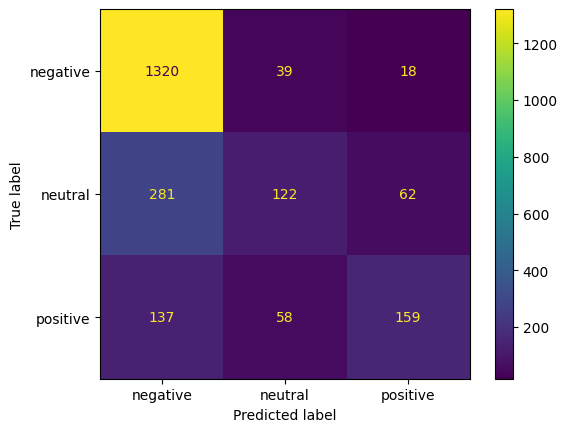

In [33]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

pred = model.predict(Xte).argmax(axis=1)
print(classification_report(y_test, pred, target_names=names))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=names).plot()
plt.show()

Training vs validation accuracy and loss

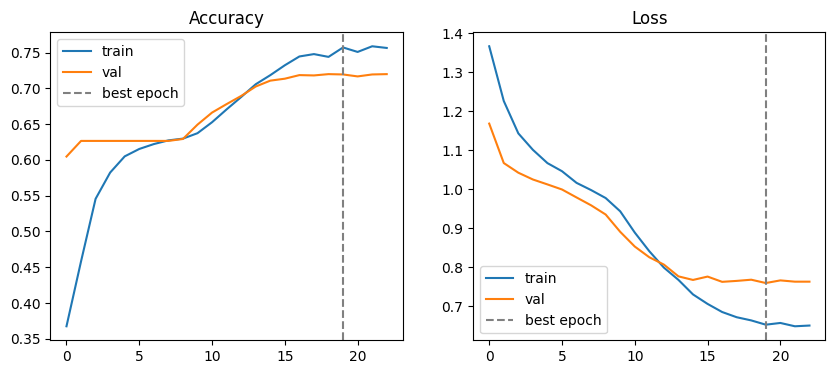

In [34]:
best = int(np.argmin(history.history["val_loss"]))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.axvline(best, color="gray", linestyle="--", label="best epoch")
plt.title("Accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.axvline(best, color="gray", linestyle="--", label="best epoch")
plt.title("Loss")
plt.legend()
plt.show()

Predict 5 new sentences with class probabilities

In [35]:
sentences = [
    "the flight was great and the crew was very friendly",
    "my bags were lost and nobody helped me",
    "flight is scheduled to depart at 5 pm",
    "worst airline ever, delayed for three hours",
    "thank you for the quick refund"
]

probs = model.predict(encode([clean(s) for s in sentences], max_len), verbose=0)
for s, p in zip(sentences, probs):
    print(s)
    print({n: round(float(v), 3) for n, v in zip(names, p)})

the flight was great and the crew was very friendly
{'negative': 0.134, 'neutral': 0.408, 'positive': 0.458}
my bags were lost and nobody helped me
{'negative': 0.901, 'neutral': 0.068, 'positive': 0.031}
flight is scheduled to depart at 5 pm
{'negative': 0.748, 'neutral': 0.169, 'positive': 0.084}
worst airline ever, delayed for three hours
{'negative': 0.996, 'neutral': 0.004, 'positive': 0.001}
thank you for the quick refund
{'negative': 0.05, 'neutral': 0.418, 'positive': 0.532}


Experiments (max_length, units, dropout, class_weight)

In [36]:
import time
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
weights = dict(enumerate(weights))

def run(setting, max_len=40, units=64, dropout=0.2, class_weight=None):
    xtr, xv, xte = encode(X_train, max_len), encode(X_val, max_len), encode(X_test, max_len)
    m = build_model(max_len, units, dropout)
    start = time.time()
    m.fit(xtr, y_train, validation_data=(xv, y_val), epochs=5, batch_size=64, class_weight=class_weight, verbose=0)
    t = time.time() - start
    p = m.predict(xte, verbose=0).argmax(axis=1)
    return [setting, round(accuracy_score(y_test, p), 4), round(f1_score(y_test, p, average="macro"), 4), round(t, 1)]

results = []
for L in [20, 40, 80]:
    results.append(run(f"max_length={L}", max_len=L))
for u in [32, 64, 128]:
    results.append(run(f"units={u}", units=u))
for d in [0.2, 0.5]:
    results.append(run(f"dropout={d}", dropout=d))
results.append(run("no class_weight"))
results.append(run("class_weight", class_weight=weights))

pd.DataFrame(results, columns=["setting", "accuracy", "macro_f1", "time_sec"])

,setting,accuracy,macro_f1,time_sec
0,max_length=20,0.6270,0.2569,15.6
1,max_length=40,0.6270,0.2569,14.4
2,max_length=80,0.6270,0.2569,16.7
3,units=32,0.6270,0.2569,14.0
4,units=64,0.6270,0.2569,13.4
5,units=128,0.6270,0.2569,14.3
6,dropout=0.2,0.6270,0.2569,14.1
7,dropout=0.5,0.6270,0.2569,13.1
8,no class_weight,0.6270,0.2569,13.3
9,class_weight,0.5974,0.4668,13.6


#Task 3

Libraries

In [37]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

Download the dataset

In [38]:
path = tf.keras.utils.get_file("shakespeare.txt", "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt")
text = open(path, "rb").read().decode("utf-8")
print(len(text))
print(text[:200])

1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1115394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you


char2idx and idx2char

In [39]:
chars = sorted(set(text))
char2idx = {c: i for i, c in enumerate(chars)}
idx2char = np.array(chars)
ids = np.array([char2idx[c] for c in text])
vocab_size = len(chars)
print(vocab_size)

65


Sequences (target shifted by one) and tf.data batching

In [40]:
def make_dataset(seq_len, batch_size=64):
    n = (len(ids) - 1) // seq_len
    x = ids[:n * seq_len].reshape(n, seq_len)
    y = ids[1:n * seq_len + 1].reshape(n, seq_len)
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    return ds.shuffle(10000).batch(batch_size, drop_remainder=True)

Build the model

In [41]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dense

def build_model(units=128, emb=64):
    model = Sequential([
        Input(shape=(None,)),
        Embedding(vocab_size, emb),
        SimpleRNN(units, return_sequences=True),
        Dense(vocab_size, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
    return model

model = build_model()
model.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_31 (Embedding)        │ (None, None, 64)       │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_31 (SimpleRNN)       │ (None, None, 128)      │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, None, 65)       │         8,385 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,249 (145.50 KB)

 Trainable params: 37,249 (145.50 KB)

 Non-trainable params: 0 (0.00 B)

Train for 15 epochs and plot the loss

Epoch 1/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 2.5188
Epoch 2/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 2.0655
Epoch 3/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.9321
Epoch 4/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.8521
Epoch 5/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 1.7974
Epoch 6/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.7583
Epoch 7/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.7282
Epoch 8/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.7049
Epoch 9/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.6861
Epoch 10/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 1.6706
Epoch 11/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 1.6571
Epoch 12/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.6459
Epoch 13/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.6360
Epoch 14/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.6271
Epoch 15/15
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - lo

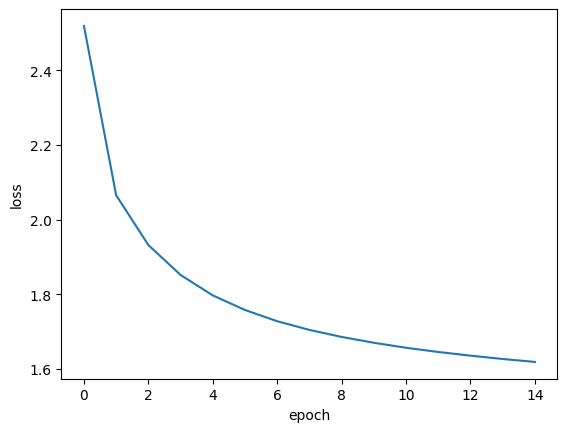

In [42]:
history = model.fit(make_dataset(50), epochs=15)

plt.plot(history.history["loss"])
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

generate_text with temperature

In [43]:
def generate_text(seed, length, temperature, net=model):
    ids_in = [char2idx[c] for c in seed]
    result = seed
    for _ in range(length):
        probs = net.predict(np.array([ids_in[-50:]]), verbose=0)[0, -1]
        logits = np.log(probs + 1e-8) / temperature
        probs = np.exp(logits - logits.max())
        probs /= probs.sum()
        next_id = np.random.choice(vocab_size, p=probs)
        ids_in.append(next_id)
        result += idx2char[next_id]
    return result

300 characters at temperatures 0.2, 0.7 and 1.2

In [44]:
seed = "ROMEO:"
for t in [0.2, 0.7, 1.2]:
    print("temperature", t)
    print(generate_text(seed, 300, t))
    print()

temperature 0.2
ROMEO:
I have so the command the sears of the send the secons of the father to my soul the seace the sun the sable the show you have me be her strange to the shall the common so many are be son, the stand the prison the subster the part the son the state the command the command and the seas of the command

temperature 0.7
ROMEO:
The it all more entrace are her her plocce you go my from my badd the prewer.

LEONTES:
Sir, that shill but the chambit, the blood?
Then this deathes wore that you make diesings by the truet I have my lears as the beggard so, baughter, stear, but she for and this noble sight of the news, by the wor

temperature 1.2
ROMEO:
Which, I id mour!

AETHARDY:
Woes, at you upond adle too nor whose be varge but of ppesce
Tithillies, one honours beg much fairlowa, that know
Ty blook;
Of eyil
to you,
Bivickmore man;
And.
He; Citil both; my be.

HORTENSIO:
Deap nor, she's Kangour wiemen you no liave.

CLAUDIO:
Unch on yours'st'm 



Experiments (sequence length and SimpleRNN units)

In [45]:
def run(seq_len, units):
    m = build_model(units)
    h = m.fit(make_dataset(seq_len), epochs=5, verbose=0)
    print("seq_len", seq_len, "units", units, "loss", round(h.history["loss"][-1], 4))
    print(generate_text(seed, 150, 0.7, m))
    print()

for L in [25, 50, 100]:
    run(L, 128)

for u in [64, 128, 256]:
    run(50, u)

seq_len 25 units 128 loss 1.755
ROMEO:
What a who-ward our house not have honest the seast be the crown. Younce
O condies and pray, to the parive beet for it farse to scord Londs of you, s

seq_len 50 units 128 loss 1.7969
ROMEO:
We to liet rest the loven:
Did fal of should best and that a good to and hay dewer the lastless many your that upon of that he not sornost be this th

seq_len 100 units 128 loss 1.8722
ROMEO:

MERY OFLY:
Where to my heperss will the gutizenst not had be gore weed no mowath to me sing,
Bownow what calle, in thy farm off the couth, with his 

seq_len 50 units 64 loss 1.9187
ROMEO:
For the steak, thereint he puce my ameary the hears the with to have, and will be the him a swent blord, you that to to me sere father with you all t

seq_len 50 units 128 loss 1.7922
ROMEO:
And your is dead the truster must Come and stisingst the beousend the with these sinst
And the laud him do becking and comport:
The grains, I will no

seq_len 50 units 256 loss 1.6808
ROMEO:
O chat

#Short Answers

## Task 1: Language Translation

1. **Why do we need an encoder and a decoder instead of one RNN?**
   The encoder compresses the English sentence into a state and the decoder generates the French sentence from it, because input and output differ in length and vocabulary.

2. **What is teacher forcing, and why is it used only during training?**
   It feeds the decoder the true previous word to speed up and stabilize learning, but at inference the true words are unknown, so the model must use its own predictions.

3. **Why does translation quality drop on longer sentences?**
   One fixed-size hidden state must hold the whole sentence, so information is lost as length grows.

4. **What does the decoder's initial hidden state represent?**
   It is the encoder's final hidden state, a compressed summary (context) of the whole English sentence.

## Task 2: Sentiment Analysis

1. **Why is softmax used here instead of sigmoid?**
   Softmax outputs probabilities over 3 mutually exclusive classes that sum to 1, while sigmoid with binary cross-entropy only handles a single two-class output (hence `sparse_categorical_crossentropy` here).

2. **Which class is hardest to predict?**
   Usually neutral, since the confusion matrix typically shows it most often confused with negative and positive, but confirm with your own matrix.

3. **How did class imbalance affect precision and recall?**
   The majority negative class gets high recall and precision while minority classes get lower recall, and `class_weight` raises minority recall at some cost to precision.

4. **How did sequence length change accuracy and training time?**
   Longer `max_length` increases training time because there are more time steps, while accuracy changes only slightly and may not improve for a SimpleRNN.

## Task 3: Text Generation

1. **How does generation differ from the many-to-one classification in Lab 03?**
   Generation predicts a next character at every time step and feeds it back in, while classification uses only the final hidden state to output one label.

2. **What does temperature do to the probability distribution?**
   It divides the logits before softmax, so low values sharpen the distribution (predictable, repetitive) and high values flatten it (diverse, random).

3. **Why does the output improve with more epochs?**
   The model keeps learning spelling, word structure and character patterns, so the loss drops and its predictions get closer to real text.

4. **Why does the generated text lose coherence over longer passages?**
   Small errors accumulate as each prediction is fed back in, and the SimpleRNN forgets earlier context because of vanishing gradients.
